# Datavera Solutions — Phase 2: Model Development, Tuning & Evaluation
**Group 4 | CSE315 Data Science**

Target: **Pass = 1 if G3 >= 10 else Fail = 0**. Split: 80/20 stratified, random_state=42.
Models: descriptive (correlation, k-Means) and predictive (Logistic Regression, Decision Tree, and tuned variants).

In [1]:
import pandas as pd, numpy as np, joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc, silhouette_score)

df = pd.read_csv('Datavera_Prepared_Model_Data.csv')
y = (df['G3'] >= 10).astype(int)
X = df.drop(columns=['G3'])
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print('Train/Test:', len(ytr), len(yte))

Train/Test: 519 130


In [2]:
# Descriptive model — k-Means clustering (unsupervised segmentation)
km = KMeans(n_clusters=5, random_state=42, n_init=10).fit(X)
print('k-Means silhouette score:', round(silhouette_score(X, km.labels_), 4))

k-Means silhouette score: 0.0972


In [3]:
# Predictive models + experiment log
models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, min_samples_leaf=5, random_state=42),
    'Tuned Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(C=0.01, class_weight='balanced', max_iter=2000, random_state=42)),
    'Tuned Decision Tree': DecisionTreeClassifier(max_depth=10, min_samples_leaf=5, random_state=42),
}
rows, fitted = [], {}
for name, m in models.items():
    m.fit(Xtr, ytr); fitted[name] = m
    p = m.predict(Xte)
    cv = cross_val_score(m, Xtr, ytr, cv=5, scoring='f1_macro').mean()
    rows.append({'Model': name, 'Training Samples': len(ytr), 'Testing Samples': len(yte),
        'Accuracy': round(accuracy_score(yte,p),4), 'Precision': round(precision_score(yte,p),4),
        'Recall': round(recall_score(yte,p),4), 'F1 Score': round(f1_score(yte,p),4),
        'Macro F1': round(f1_score(yte,p,average='macro'),4), 'Fail Recall': round(recall_score(yte,p,pos_label=0),4),
        'CV Macro F1': round(cv,4)})
log = pd.DataFrame(rows)
log.to_csv('Datavera_Model_Experiment_Log.csv', index=False)
log

,Model,Training Samples,Testing Samples,Accuracy,Precision,Recall,F1 Score,Macro F1,Fail Recall,CV Macro F1
0,Logistic Regression,519,130,0.7923,0.8673,0.8909,0.8789,0.5746,0.25,0.6710
1,Decision Tree,519,130,0.7615,0.8559,0.8636,0.8597,0.5324,0.20,0.6964
2,Tuned Logistic Regression,519,130,0.6538,0.8824,0.6818,0.7692,0.5385,0.50,0.7189
3,Tuned Decision Tree,519,130,0.7769,0.8584,0.8818,0.8700,0.5431,0.20,0.7225


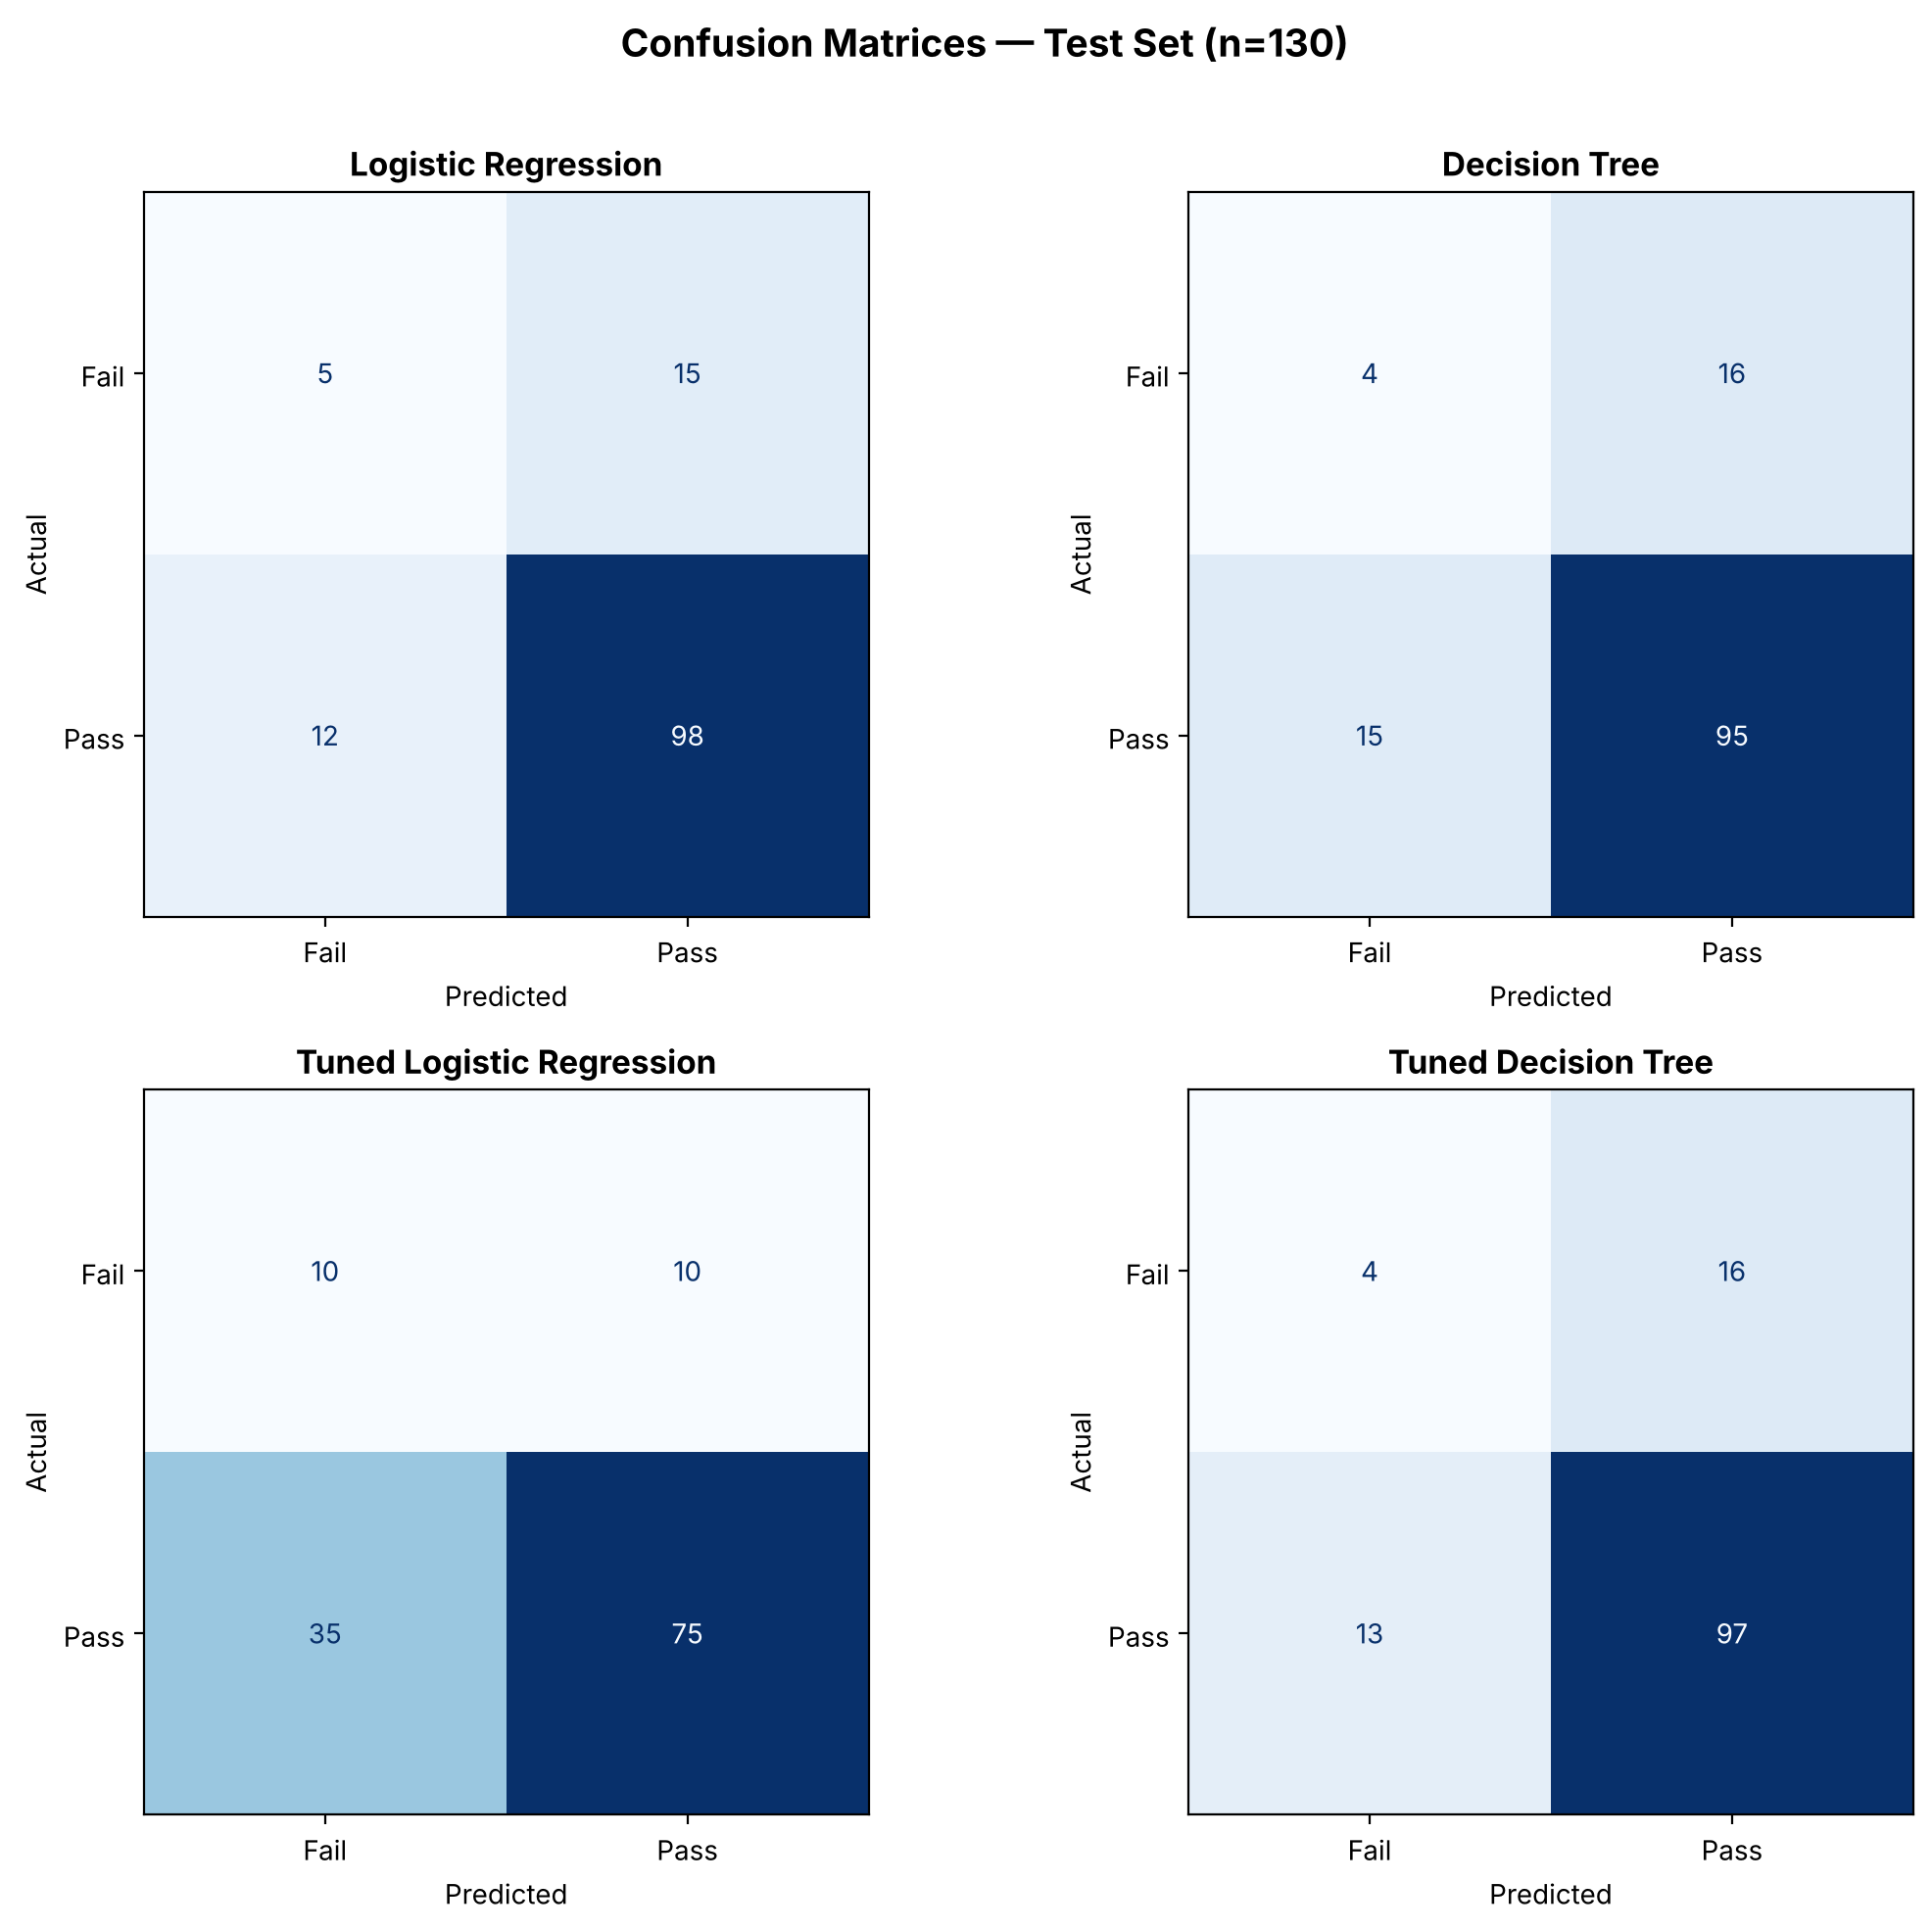

In [4]:
# Confusion matrices (held-out test set)
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ax, (name, m) in zip(axes.ravel(), fitted.items()):
    cm = confusion_matrix(yte, m.predict(Xte))
    ConfusionMatrixDisplay(cm, display_labels=['Fail','Pass']).plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(name, fontweight='bold'); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
fig.suptitle('Confusion Matrices — Test Set (n=130)', fontsize=14, fontweight='bold')
fig.tight_layout(rect=[0,0,1,0.97]); fig.savefig('Confusion_Matrices_All.png', dpi=150, bbox_inches='tight'); plt.show()

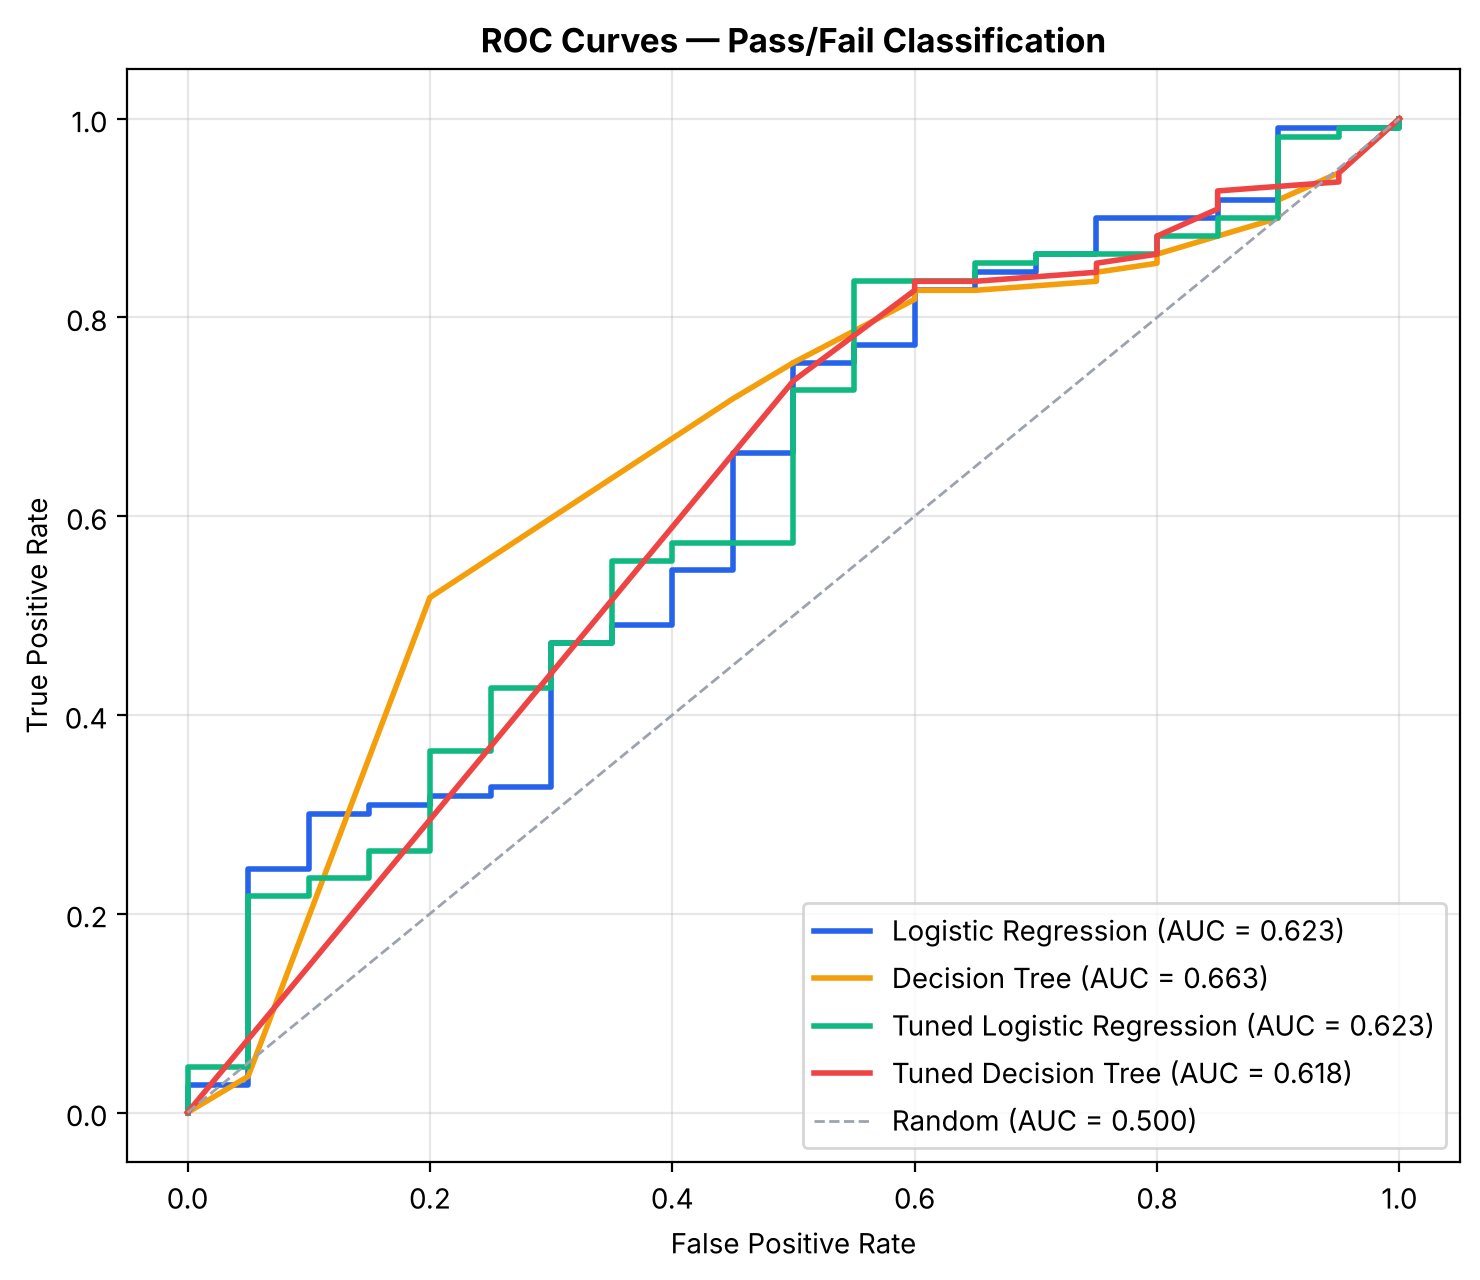

In [5]:
# ROC curves and AUC
colors = {'Logistic Regression':'#2563eb','Decision Tree':'#f59e0b','Tuned Logistic Regression':'#10b981','Tuned Decision Tree':'#ef4444'}
plt.figure(figsize=(7.5, 6.5))
for name, m in fitted.items():
    proba = m.predict_proba(Xte)[:,1]
    fpr, tpr, _ = roc_curve(yte, proba); a = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=colors[name], lw=2, label=f'{name} (AUC = {a:.3f})')
plt.plot([0,1],[0,1],'--',color='#9ca3af',lw=1,label='Random (AUC = 0.500)')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curves — Pass/Fail Classification', fontweight='bold')
plt.legend(loc='lower right'); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('ROC_Curves_All.png', dpi=150, bbox_inches='tight'); plt.show()

In [6]:
# Export final model artifact — Tuned Logistic Regression (chosen by Fail Recall)
final = fitted['Tuned Logistic Regression']
p = final.predict(Xte)
artifact = {'model': final, 'model_name': 'Tuned Logistic Regression',
    'selection_rationale': 'Selected by Fail Recall to match the early-warning goal (identify at-risk students).',
    'feature_names': list(X.columns), 'target': 'Pass/Fail', 'target_rule': 'Pass = 1 if G3 >= 10 else Fail = 0',
    'class_labels': {0:'Fail', 1:'Pass'}, 'positive_class': 1,
    'training_samples': len(ytr), 'testing_samples': len(yte), 'random_state': 42,
    'model_metrics': {'accuracy': round(accuracy_score(yte,p),4), 'fail_recall': round(recall_score(yte,p,pos_label=0),4),
        'macro_f1': round(f1_score(yte,p,average='macro'),4)}}
joblib.dump(artifact, 'model_artifacts.pkl')
print('Saved model_artifacts.pkl —', artifact['model_name'], artifact['model_metrics'])

Saved model_artifacts.pkl — Tuned Logistic Regression {'accuracy': 0.6538, 'fail_recall': 0.5, 'macro_f1': 0.5385}


### Final model selection
**Tuned Logistic Regression** is the deployment model. Although its accuracy (0.65) is lower than the baselines, it achieves the highest **Fail Recall (0.50)** — it correctly flags half of at-risk students, which is the project's early-warning objective. High-accuracy models (0.79) detect only 20–25% of failures.

**Limitation:** AUC is modest (~0.62); future work includes decision-threshold tuning and resampling (SMOTE) to further raise recall.